In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# train = pd.read_csv("train.csv")
# test = pd.read_csv("test.csv")
# submission = pd.read_csv("sample_submission.csv")

# Overview
Workspaces rent at very different prices, and what a space can charge depends on many factors. Where it sits, what it offers, how it is booked, how busy it stays and who runs it all play a part.

In this competition you are given listings for bookable workspaces, each described by its location, physical attributes, facilities, booking terms, availability and review history. Your task is to predict the price tier of each listing from these attributes.

# loading the dataset


In [3]:

train = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv")
test = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv")
submission = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv")

In [4]:
train.head()

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2
3,3,Spesspe,2.0,1.0,2.0,1.0,unverified_operator,t,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.60,MTR-09,4
4,4,Gosho,2.0,7.0,2.0,4.0,unverified_operator,t,1.0,t,...,9.42,9.74,licensed,1,1,0,0,4.64,MTR-08,3


# Info of the dataset

In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279746 entries, 0 to 279745
Data columns (total 60 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   space_id                      279746 non-null  int64  
 1   operator_ref                  279142 non-null  object 
 2   operator_platform_age_years   279142 non-null  float64
 3   operator_platform_age_months  279142 non-null  float64
 4   operator_active_years         279140 non-null  float64
 5   operator_active_months        279140 non-null  float64
 6   operator_class                279746 non-null  object 
 7   operator_certified            279142 non-null  object 
 8   operator_portfolio_size       279142 non-null  float64
 9   operator_has_avatar           279142 non-null  object 
 10  operator_id_verified          279142 non-null  object 
 11  zone                          279746 non-null  object 
 12  borough                       65295 non-null

Dataset shape: (279746, 60)

Target data type: int64

Unique price tiers:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Class counts:
price_tier
1    66889
2    81530
3    60839
4    70488
Name: count, dtype: int64

Class percentages:
price_tier
1    23.91
2    29.14
3    21.75
4    25.20
Name: proportion, dtype: float64


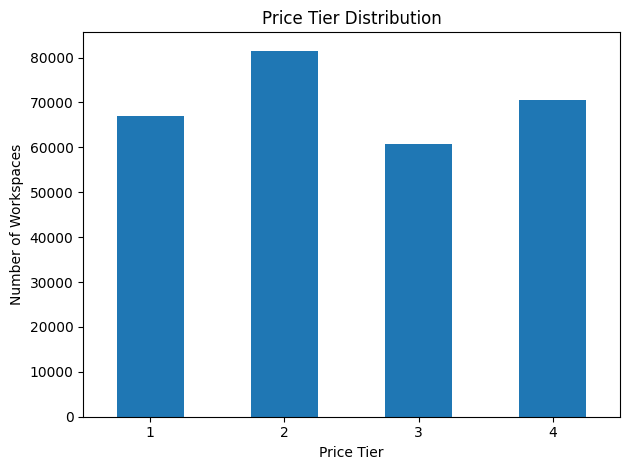

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Basic dataset information
print("Dataset shape:", train.shape)
print("\nTarget data type:", train["price_tier"].dtype)

# Check target classes
print("\nUnique price tiers:")
print(sorted(train["price_tier"].dropna().unique()))

# Class distribution
print("\nClass counts:")
print(train["price_tier"].value_counts().sort_index())

print("\nClass percentages:")
print(
    (train["price_tier"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Visualize class distribution
train["price_tier"].value_counts().sort_index().plot(
    kind="bar",
    xlabel="Price Tier",
    ylabel="Number of Workspaces",
    title="Price Tier Distribution",
    rot=0
)

plt.tight_layout()
plt.show()


In [7]:
train.describe()

,space_id,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_portfolio_size,geo_lat,geo_lon,max_seats,utility_rooms,...,score_onboarding,score_support,score_access,score_value,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,price_tier
count,279746.00000,279142.000000,279142.000000,279140.000000,279140.000000,279142.000000,279746.000000,279746.000000,279746.000000,249847.000000,...,225503.000000,225505.000000,225501.000000,225500.000000,279746.000000,279746.000000,279746.000000,279746.000000,225506.000000,279746.000000
mean,139872.50000,6.794735,5.453275,5.083295,5.298635,49.472043,77.766908,-35.144810,3.627312,1.358645,...,9.633323,9.651561,9.559088,9.302167,22.630883,18.468203,3.905736,0.098940,1.528739,2.482316
std,80755.85854,4.187652,3.489590,4.040029,3.480848,332.752235,37.513760,57.170057,2.277564,0.806307,...,0.750909,0.772645,0.718961,0.915583,58.731714,54.515981,19.515136,1.370754,1.808781,1.109886
min,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,-4.818000,-123.749800,1.000000,0.500000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000,1.000000
25%,69936.25000,3.000000,2.000000,2.000000,2.000000,1.000000,68.041500,-76.559800,2.000000,1.000000,...,9.600000,9.620000,9.420000,9.120000,1.000000,1.000000,0.000000,0.000000,0.340000,2.000000
50%,139872.50000,7.000000,5.000000,4.000000,5.000000,4.000000,94.623000,-31.132600,3.000000,1.000000,...,9.840000,9.880000,9.760000,9.520000,3.000000,2.000000,0.000000,0.000000,1.000000,2.000000
75%,209808.75000,10.000000,9.000000,8.000000,8.000000,19.000000,100.941000,-21.265600,4.000000,1.500000,...,10.000000,10.000000,10.000000,9.800000,15.000000,10.000000,1.000000,0.000000,2.190000,4.000000
max,279745.00000,17.000000,11.000000,15.000000,11.000000,5978.000000,111.768000,87.045200,16.000000,50.000000,...,10.000000,10.000000,10.000000,10.000000,754.000000,754.000000,233.000000,62.000000,150.180000,4.000000


In [8]:

# Separate numerical features from the target
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [col for col in numeric_cols if col != "price_tier"]

# Spearman correlation with price_tier
target_corr = (
    train[numeric_cols + ["price_tier"]]
    .corr(method="spearman")["price_tier"]
    .drop("price_tier")
    .sort_values(key=abs, ascending=False)
)

print("Top 20 numerical features related to price_tier:")
print(target_corr.head(20).round(3))

Top 20 numerical features related to price_tier:
max_seats                      0.501
zones                          0.451
workstations                   0.427
geo_lat                        0.348
utility_rooms                  0.312
operator_metro_private        -0.311
operator_metro_whole           0.168
open_slots_c                  -0.161
open_slots_b                  -0.160
open_slots_a                  -0.144
min_term_floor                -0.125
min_term_days                 -0.125
operator_metro_shared         -0.116
score_access                   0.112
open_slots_e                  -0.090
review_count_30d               0.086
open_slots_d                  -0.084
reviews_per_month              0.074
operator_platform_age_years    0.070
review_count_12m               0.065
Name: price_tier, dtype: float64


In [9]:
# Compare feature medians across price tiers
top_features = target_corr.head(10).index.tolist()

tier_summary = train.groupby("price_tier")[top_features].median().T

print(tier_summary.round(2))

price_tier                  1      2      3      4
max_seats                2.00   2.00   4.00   5.00
zones                    1.00   1.00   1.00   2.00
workstations             1.00   1.00   2.00   3.00
geo_lat                 60.82  94.26  97.11  98.55
utility_rooms            1.00   1.00   1.00   1.50
operator_metro_private   1.00   0.00   0.00   0.00
operator_metro_whole     1.00   2.00   2.00   2.00
open_slots_c            76.00  62.00  55.00  56.00
open_slots_b            49.00  37.00  32.00  32.00
open_slots_a            22.00  14.00  12.00  12.00


# identify and handle missing values


In [10]:
train.isnull().sum()

space_id                             0
operator_ref                       604
operator_platform_age_years        604
operator_platform_age_months       604
operator_active_years              606
operator_active_months             606
operator_class                       0
operator_certified                 604
operator_portfolio_size            604
operator_has_avatar                604
operator_id_verified               604
zone                                 0
borough                         214451
geo_lat                              0
geo_lon                              0
space_class                          0
access_type                          0
max_seats                            0
utility_rooms                    29899
zones                            48414
workstations                     18783
facilities                           0
snapshot_start_date                  0
snapshot_end_date                    0
min_term_days                       41
max_term_days            

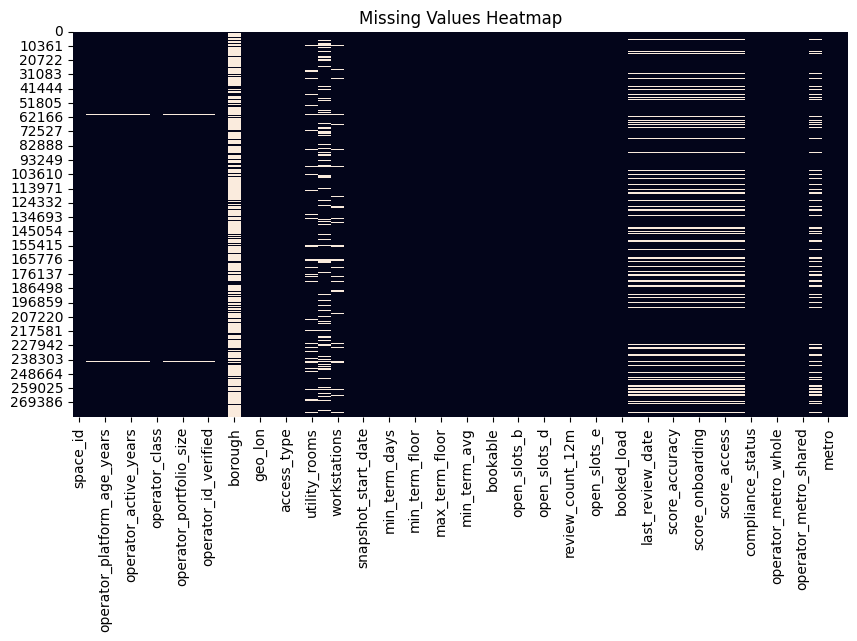

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.heatmap(train.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

## To handle missing values:
### Numarical values:
- replace numarical values with the `mean`
- replace the catogorical values with the `most_frequently`/`mode` used

In [12]:
from sklearn.model_selection import train_test_split
X = train.drop(['price_tier','space_id'],axis=1,errors="ignore")
y = train['price_tier']

x_train, x_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=10, stratify=y)

num_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_columns = X.select_dtypes(include=['object', 'category']).columns.tolist()

In [13]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin

class GeoCleaner(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X.loc[~X["geo_lat"].between(-90, 90), "geo_lat"] = np.nan
        X.loc[~X["geo_lon"].between(-180, 180), "geo_lon"] = np.nan

        return X


class CategoricalCleaner(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col in X.select_dtypes(
            include=["object", "category"]
        ).columns:
            X[col] = X[col].fillna("Missing").astype(str)

        return X

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

sklearn_preprocessor = Pipeline([
    ("geo_cleaner", GeoCleaner()),
    ("columns", ColumnTransformer([
        ("numerical", numerical_pipeline, num_columns),
        ("categorical", categorical_pipeline, cat_columns)
    ]))
])

sklearn_preprocessor

Pipeline(steps=[('geo_cleaner', GeoCleaner()),
                ('columns',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['operator_platform_age_years',
                                                   'operator_platform_age_months',
                                                   'operator_active_years',
                                                   'operator_active_months',
                                                   'operator_portfolio_size',
                                                   'geo_lat', 'geo_lon',
                                                   '...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['operator_ref',
                                                   'operator_class',
                                                   'operator_certified',
                                                   'operator_has_avatar',
                                                   'operator_id_verified',
                                                   'zone', 'borough',
                                                   'space_class', 'access_type',
                                                   'facilities',
                                                   'snapshot_start_date',
                                                   'snapshot_end_date',
                                                   'bookable',
                                                   'first_review_date',
                                                   'last_review_date',
                                                   'compliance_status',
                                                   'metro'])]))])

In [15]:
catboost_preprocessor = Pipeline([
    ("geo_cleaner", GeoCleaner()),
    ("categorical_cleaner", CategoricalCleaner())
])
catboost_preprocessor

Pipeline(steps=[('geo_cleaner', GeoCleaner()),
                ('categorical_cleaner', CategoricalCleaner())])

In [16]:
# ARCHIVED - old random-split baseline (val accuracy 0.7259, but the Kaggle test score was only ~0.68).
# Kept commented out so 'Run All' does not retrain it. The outputs below are the saved record.
# (The `!pip install catboost` line moved to the next section.)
#
#
# from catboost import CatBoostClassifier
# from sklearn.pipeline import Pipeline
# from sklearn.metrics import accuracy_score, f1_score
# import pandas as pd
#
# # Ensure all categorical columns in our training and testing data splits are strings with filled NaNs
# for col in cat_columns:
#     x_train[col] = x_train[col].fillna("Missing").astype(str)
#     x_test[col] = x_test[col].fillna("Missing").astype(str)
#
# catboost_model = Pipeline([
#     ("preprocessor", catboost_preprocessor),
#     ("model", CatBoostClassifier(
#         iterations=1500,
#         learning_rate=0.05,
#         depth=8,
#         loss_function="MultiClass",
#         eval_metric="Accuracy",
#         l2_leaf_reg=5,
#         random_seed=42,
#         verbose=200,
#         early_stopping_rounds=100,
#         thread_count=-1,
#         allow_writing_files=True,
#         save_snapshot=True,
#         snapshot_file='catboost_model_training_checkpoint.dump',
#         snapshot_interval=60  # Saves progress to file every 60 seconds
#     ))
# ])
#
# catboost_model.fit(
#     x_train,
#     y_train,
#     model__cat_features=cat_columns,
#     model__eval_set=(x_test, y_test)
# )
#
# preds = catboost_model.predict(x_test).flatten()
#
# print("Accuracy:", accuracy_score(y_test, preds))
# print("F1:", f1_score(y_test, preds, average="macro"))

# Final modelling (rebuilt)

**Why this section was rebuilt**
- The random 70/30 split put the *same operators* in train and validation, so validation (0.726) was too optimistic vs. the Kaggle test (~0.68). All experiments below use a **group split by `operator_ref`**, which is much closer to the real test.
- `engineer_features` is now actually **validated** (A/B/C experiments) before being used for the final submission.
- Every run is **resumable** (CatBoost snapshots) and **saved to disk** (`.cbm`), so re-running a finished cell loads the model instead of retraining.
- GPU is used automatically if available.

**If a run is interrupted:** just re-run the same cell with the same parameters and data. If you *change* parameters, delete that run's folder inside `cb_runs/` first (CatBoost refuses to resume a snapshot with different settings).

In [17]:
!pip install catboost -q

In [18]:
import os
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from catboost.utils import get_gpu_device_count
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score

# ---- config ----
SEED = 42
EXP_LR = 0.1        # fast learning rate for A/B/C experiments
FINAL_LR = 0.05     # slower learning rate for the one final run
EXP_ITERS = 1500

TASK_TYPE = "GPU" if get_gpu_device_count() > 0 else "CPU"
print("CatBoost task type:", TASK_TYPE, "(switch the runtime to GPU if this says CPU - it is MUCH faster)")

# snapshots + saved models live here (kept across restarts if the folder persists)
WORK_DIR = "/kaggle/working/cb_runs" if os.path.exists("/kaggle/working") else "cb_runs"
os.makedirs(WORK_DIR, exist_ok=True)
print("Run folder:", WORK_DIR)

CatBoost task type: GPU (switch the runtime to GPU if this says CPU - it is MUCH faster)
Run folder: /kaggle/working/cb_runs


## 1. Why validation (0.726) and test (~0.68) disagree

In [19]:
def seen_rate(df_a, df_b):
    """Share of rows in df_a whose operator also appears in df_b."""
    a = df_a["operator_ref"].dropna()
    return a.isin(df_b["operator_ref"].dropna().unique()).mean()

print("Test rows whose operator exists in train      :", round(seen_rate(test, train), 3))
print("Old random-split val rows seen in train part  :", round(seen_rate(x_test, x_train), 3))
# If the second number is much higher than the first, the old validation score was inflated.

Test rows whose operator exists in train      : 0.664
Old random-split val rows seen in train part  : 0.905


In [20]:
# Honest validation: split by operator so an operator never appears in both train and validation.
# Rows with a missing operator each get their own group.
y_all = train["price_tier"].astype(int)
groups = np.where(train["operator_ref"].notna(),
                  train["operator_ref"].astype(str),
                  "missing_" + train.index.astype(str))

gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=10)
tr_idx, va_idx = next(gss.split(train, y_all, groups=groups))

print("train rows:", len(tr_idx), "| val rows:", len(va_idx))
print("Group-split val rows seen in train part:", round(seen_rate(train.iloc[va_idx], train.iloc[tr_idx]), 3))

train rows: 195454 | val rows: 84292
Group-split val rows seen in train part: 0.0


## 2. Feature engineering (`engineer_features`)

In [21]:
DATE_COLS = ["snapshot_start_date", "snapshot_end_date", "first_review_date", "last_review_date"]

def engineer_features(df, cat_cols):
    df = df.copy()

    # 1. clean coordinates
    df.loc[~df["geo_lat"].between(-90, 90), "geo_lat"] = np.nan
    df.loc[~df["geo_lon"].between(-180, 180), "geo_lon"] = np.nan

    # 2. date features (parse into a side dict; the raw date strings are dropped at the end)
    d = {c: pd.to_datetime(df[c], errors="coerce") for c in DATE_COLS if c in df.columns}
    df["days_since_first_review"] = (d["snapshot_start_date"] - d["first_review_date"]).dt.days
    df["days_since_last_review"]  = (d["snapshot_start_date"] - d["last_review_date"]).dt.days
    df["snapshot_span_days"]      = (d["snapshot_end_date"] - d["snapshot_start_date"]).dt.days
    df["snapshot_month"]          = d["snapshot_start_date"].dt.month
    df["snapshot_year"]           = d["snapshot_start_date"].dt.year

    # 3. capacity / operator ratios
    df["seats_per_workstation"] = df["max_seats"] / (df["workstations"] + 1)
    df["utility_ratio"] = df["utility_rooms"] / (df["max_seats"] + 1)
    df["operator_total_age_months"] = df["operator_platform_age_years"] * 12 + df["operator_platform_age_months"]
    df["operator_active_months_total"] = df["operator_active_years"] * 12 + df["operator_active_months"]
    df["operator_active_ratio"] = df["operator_active_months_total"] / (df["operator_total_age_months"] + 1)

    # 4. booking-term and review ratios
    df["term_range"] = df["max_term_days"] - df["min_term_days"]
    df["reviews_12m_ratio"] = df["review_count_12m"] / (df["review_count"] + 1)

    # 5. facilities count
    fac = df["facilities"].fillna("")
    df["num_facilities"] = fac.apply(lambda x: len(x.split(",")) if x else 0)

    # 6. drop raw date strings, fill categoricals
    df = df.drop(columns=[c for c in DATE_COLS if c in df.columns])
    for col in cat_cols:
        if col in df.columns:
            df[col] = df[col].fillna("Missing").astype(str)
    return df


cat_cols_model = [c for c in cat_columns if c not in DATE_COLS]

train_fe = engineer_features(train, cat_cols_model)
test_fe  = engineer_features(test,  cat_cols_model)

# --- Feature set A: raw columns (same idea as the old baseline, dates kept as categoricals) ---
def make_raw(df):
    out = df.drop(columns=["price_tier", "space_id"], errors="ignore").copy()
    for c in cat_columns:
        out[c] = out[c].fillna("Missing").astype(str)
    return out

X_raw, X_raw_test = make_raw(train), make_raw(test)

# --- Feature set B: engineered ---
fe_cols = [c for c in train_fe.columns if c not in ["price_tier", "space_id"]]
X_fe, X_fe_test = train_fe[fe_cols], test_fe[fe_cols]

# --- Feature set C: engineered, without operator_ref (tests whether operator identity hurts generalisation) ---
fe_cols_c = [c for c in fe_cols if c != "operator_ref"]
cats_c = [c for c in cat_cols_model if c != "operator_ref"]
X_fe_c, X_fe_c_test = train_fe[fe_cols_c], test_fe[fe_cols_c]

FEATURE_SETS = {
    "A_raw":            (X_raw,  X_raw_test,  cat_columns),
    "B_engineered":     (X_fe,   X_fe_test,   cat_cols_model),
    "C_eng_no_operator": (X_fe_c, X_fe_c_test, cats_c),
}
for k, (a, b, c) in FEATURE_SETS.items():
    print(f"{k:18s} train {a.shape} | test {b.shape} | cat cols {len(c)}")

A_raw              train (279746, 58) | test (114538, 58) | cat cols 17
B_engineered       train (279746, 67) | test (114538, 67) | cat cols 13
C_eng_no_operator  train (279746, 66) | test (114538, 66) | cat cols 12


## 3. Experiments on the honest (operator-grouped) split

Each experiment saves its model and a resumable snapshot. Re-running a finished cell loads the saved model instantly.

In [22]:
results = {}

def run_experiment(name, X, cat_cols, lr=EXP_LR, iterations=EXP_ITERS):
    run_dir = os.path.join(WORK_DIR, name)
    model_path = os.path.join(run_dir, f"{name}.cbm")
    Xtr, Xva = X.iloc[tr_idx], X.iloc[va_idx]
    ytr, yva = y_all.iloc[tr_idx], y_all.iloc[va_idx]

    model = CatBoostClassifier(
        iterations=iterations, learning_rate=lr, depth=8, l2_leaf_reg=5,
        loss_function="MultiClass", eval_metric="Accuracy",
        early_stopping_rounds=100, random_seed=SEED, task_type=TASK_TYPE,
        train_dir=run_dir, allow_writing_files=True,
        save_snapshot=True, snapshot_file=f"{name}.snapshot", snapshot_interval=300,
        verbose=100,
    )

    if os.path.exists(model_path):
        print(f"[{name}] finished model found - loading it instead of retraining")
        model.load_model(model_path)
    else:
        model.fit(Xtr, ytr, cat_features=cat_cols, eval_set=(Xva, yva), use_best_model=True)
        model.save_model(model_path)

    preds = model.predict(Xva).flatten().astype(int)
    res = {
        "name": name,
        "accuracy": accuracy_score(yva, preds),
        "macro_f1": f1_score(yva, preds, average="macro"),
        "trees": model.tree_count_,
    }
    print(f"[{name}] acc={res['accuracy']:.4f}  macroF1={res['macro_f1']:.4f}  trees={res['trees']}")
    return res

In [23]:
results["A_raw"] = run_experiment("A_raw", *[FEATURE_SETS["A_raw"][i] for i in (0, 2)])

0:	learn: 0.5817737	test: 0.5850140	best: 0.5850140 (0)	total: 177ms	remaining: 4m 24s
100:	learn: 0.6890931	test: 0.6695653	best: 0.6695653 (100)	total: 3.09s	remaining: 42.8s
200:	learn: 0.7128122	test: 0.6802069	best: 0.6802069 (200)	total: 5.82s	remaining: 37.6s
300:	learn: 0.7272044	test: 0.6856760	best: 0.6856760 (300)	total: 8.33s	remaining: 33.2s
400:	learn: 0.7380714	test: 0.6873250	best: 0.6876335 (383)	total: 11s	remaining: 30.1s
500:	learn: 0.7483295	test: 0.6887486	best: 0.6892350 (493)	total: 13.5s	remaining: 27s
600:	learn: 0.7575542	test: 0.6894486	best: 0.6899943 (520)	total: 16.2s	remaining: 24.2s
bestTest = 0.6899943055
bestIteration = 520
Shrink model to first 521 iterations.
[A_raw] acc=0.6900  macroF1=0.6862  trees=521


In [24]:
results["B_engineered"] = run_experiment("B_engineered", *[FEATURE_SETS["B_engineered"][i] for i in (0, 2)])

0:	learn: 0.5821472	test: 0.5852631	best: 0.5852631 (0)	total: 60.9ms	remaining: 1m 31s
100:	learn: 0.6934880	test: 0.6738718	best: 0.6738718 (100)	total: 2.81s	remaining: 38.9s
200:	learn: 0.7171611	test: 0.6850116	best: 0.6853438 (196)	total: 5.54s	remaining: 35.8s
300:	learn: 0.7319779	test: 0.6893537	best: 0.6893537 (300)	total: 8.15s	remaining: 32.5s
400:	learn: 0.7424816	test: 0.6929602	best: 0.6929602 (400)	total: 10.7s	remaining: 29.4s
500:	learn: 0.7521923	test: 0.6935296	best: 0.6939449 (465)	total: 13.2s	remaining: 26.4s
600:	learn: 0.7605319	test: 0.6948821	best: 0.6949295 (595)	total: 15.7s	remaining: 23.5s
700:	learn: 0.7691119	test: 0.6947279	best: 0.6954159 (675)	total: 18.2s	remaining: 20.7s
bestTest = 0.6954159351
bestIteration = 675
Shrink model to first 676 iterations.
[B_engineered] acc=0.6954  macroF1=0.6911  trees=676


In [25]:
results["C_eng_no_operator"] = run_experiment("C_eng_no_operator", *[FEATURE_SETS["C_eng_no_operator"][i] for i in (0, 2)])

0:	learn: 0.5821472	test: 0.5852631	best: 0.5852631 (0)	total: 47.6ms	remaining: 1m 11s
100:	learn: 0.6896508	test: 0.6769088	best: 0.6769800 (99)	total: 2.87s	remaining: 39.8s
200:	learn: 0.7142397	test: 0.6880843	best: 0.6880843 (200)	total: 5.57s	remaining: 36s
300:	learn: 0.7275216	test: 0.6926280	best: 0.6926280 (300)	total: 8.18s	remaining: 32.6s
400:	learn: 0.7381481	test: 0.6943126	best: 0.6945380 (385)	total: 10.7s	remaining: 29.4s
500:	learn: 0.7475826	test: 0.6960091	best: 0.6961752 (486)	total: 13.3s	remaining: 26.5s
600:	learn: 0.7564286	test: 0.6972666	best: 0.6973853 (591)	total: 16s	remaining: 23.9s
700:	learn: 0.7648040	test: 0.6982988	best: 0.6982988 (700)	total: 18.8s	remaining: 21.4s
800:	learn: 0.7723352	test: 0.6984055	best: 0.6991055 (773)	total: 21.4s	remaining: 18.7s
bestTest = 0.6991054904
bestIteration = 773
Shrink model to first 774 iterations.
[C_eng_no_operator] acc=0.6991  macroF1=0.6945  trees=774


In [26]:
results_df = pd.DataFrame(results.values()).sort_values("accuracy", ascending=False).reset_index(drop=True)
display(results_df)
best_name = results_df.loc[0, "name"]
print("Best feature set:", best_name)

,name,accuracy,macro_f1,trees
0,C_eng_no_operator,0.699105,0.694470,774
1,B_engineered,0.695416,0.691122,676
2,A_raw,0.689994,0.686194,521


Best feature set: C_eng_no_operator


## 4. Better final model: 5-fold grouped CV + CatBoost/LightGBM blend + class weights

The single "train on 100%" model is replaced by:
1. **Group features** (operator size, listing vs. zone/metro medians) - label-free, so no leakage.
2. **5-fold CatBoost CV**, folds grouped by operator. Test predictions = average of the 5 fold models. Every fold is saved and **resumable**.
3. **LightGBM** on the same folds, then a **blend** whose ratio is chosen on out-of-fold (OOF) predictions.
4. **Per-class probability weights** tuned on OOF predictions (tiers are ordered; most errors are between neighbouring tiers).

The OOF accuracy printed here is your honest estimate of the test score (expect it ~0.5-1 point optimistic).
Needs GPU for CatBoost to be fast. If a cell is interrupted, re-run it: finished folds load from disk.

### 4.1 Group features + 5 operator-grouped folds

In [27]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix

def add_group_features(tr, te):
    """Label-free features: operator size + 'how does this listing compare to its location peers'."""
    full = pd.concat([tr.assign(_is_train=1), te.assign(_is_train=0)], ignore_index=True)

    full["operator_listing_count"] = full.groupby("operator_ref")["max_seats"].transform("size")
    full["operator_mean_seats"]    = full.groupby("operator_ref")["max_seats"].transform("mean")
    missing_op = full["operator_ref"] == "Missing"          # all unknown operators share one label -> meaningless stats
    full.loc[missing_op, ["operator_listing_count", "operator_mean_seats"]] = np.nan

    for key in ["metro", "zone"]:
        for col in ["max_seats", "workstations", "utility_rooms", "zones"]:
            full[f"{col}_vs_{key}_median"] = full[col] - full.groupby(key)[col].transform("median")
        full[f"{key}_listing_count"] = full.groupby(key)["max_seats"].transform("size")

    new_cols = [c for c in full.columns if c not in tr.columns and c != "_is_train"]
    g_tr = full.loc[full["_is_train"] == 1, new_cols].set_axis(tr.index, axis=0)
    g_te = full.loc[full["_is_train"] == 0, new_cols].set_axis(te.index, axis=0)
    return g_tr, g_te, new_cols

g_tr, g_te, g_cols = add_group_features(train_fe, test_fe)

# Automatic: drop operator_ref if experiment C (no operator) beat experiment B in section 3.
# You can override by hard-coding True/False here.
try:
    DROP_OPERATOR_REF = results["C_eng_no_operator"]["accuracy"] > results["B_engineered"]["accuracy"]
except KeyError:
    DROP_OPERATOR_REF = False
print("DROP_OPERATOR_REF =", DROP_OPERATOR_REF)
base_cols = fe_cols_c if DROP_OPERATOR_REF else fe_cols
cats_d = [c for c in cat_cols_model if c in base_cols]

X_d      = pd.concat([train_fe[base_cols], g_tr], axis=1)
X_d_test = pd.concat([test_fe[base_cols],  g_te], axis=1)
FEATURE_SETS["D_group"] = (X_d, X_d_test, cats_d)
print("D_group:", X_d.shape, "| new features:", len(g_cols))

# 5 folds, grouped by operator, class balance preserved. Every model below uses the SAME folds.
N_FOLDS = 5
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(sgkf.split(X_d, y_all, groups=groups))
y_np = y_all.values

DROP_OPERATOR_REF = True
D_group: (279746, 78) | new features: 12


### 4.2 CatBoost 5-fold CV

In [28]:
CV_LR = 0.06

def run_cv_catboost(tag, X, X_test, cats, lr=CV_LR, iterations=3000, seed=SEED):
    oof = np.zeros((len(X), 4))
    test_p = np.zeros((len(X_test), 4))
    X_test = X_test[X.columns]
    for k, (tr, va) in enumerate(folds):
        name = f"{tag}_fold{k}"
        run_dir = os.path.join(WORK_DIR, name)
        path = os.path.join(run_dir, name + ".cbm")
        m = CatBoostClassifier(
            iterations=iterations, learning_rate=lr, depth=8, l2_leaf_reg=5,
            loss_function="MultiClass", eval_metric="MultiClass", custom_metric=["Accuracy"],
            early_stopping_rounds=150, random_seed=seed, task_type=TASK_TYPE,
            train_dir=run_dir, allow_writing_files=True,
            save_snapshot=True, snapshot_file=name + ".snapshot", snapshot_interval=300,
            verbose=200,
        )
        if os.path.exists(path):
            print(f"[{name}] saved model found - loading")
            m.load_model(path)
        else:
            m.fit(X.iloc[tr], y_all.iloc[tr], cat_features=cats,
                  eval_set=(X.iloc[va], y_all.iloc[va]), use_best_model=True)
            m.save_model(path)
        oof[va] = m.predict_proba(X.iloc[va])
        test_p += m.predict_proba(X_test) / N_FOLDS
        print(f"[{name}] fold acc = {(oof[va].argmax(1) + 1 == y_np[va]).mean():.4f}  trees = {m.tree_count_}")
    print(f"[{tag}] OOF accuracy = {(oof.argmax(1) + 1 == y_np).mean():.4f}")
    np.save(os.path.join(WORK_DIR, f"{tag}_oof.npy"), oof)
    np.save(os.path.join(WORK_DIR, f"{tag}_test.npy"), test_p)
    return oof, test_p

Xd, Xd_test, cd = FEATURE_SETS["D_group"]
oof_cb, test_cb = run_cv_catboost("cb_D", Xd, Xd_test, cd)

0:	learn: 1.3355352	test: 1.3361256	best: 1.3361256 (0)	total: 52.3ms	remaining: 2m 36s
200:	learn: 0.7076947	test: 0.7381058	best: 0.7381058 (200)	total: 5.6s	remaining: 1m 17s
400:	learn: 0.6592223	test: 0.7112764	best: 0.7112764 (400)	total: 11s	remaining: 1m 11s
600:	learn: 0.6305209	test: 0.7007274	best: 0.7007274 (600)	total: 16.1s	remaining: 1m 4s
800:	learn: 0.6103206	test: 0.6951057	best: 0.6950834 (799)	total: 21.1s	remaining: 57.9s
1000:	learn: 0.5922878	test: 0.6913076	best: 0.6913048 (999)	total: 26.1s	remaining: 52.1s
1200:	learn: 0.5754885	test: 0.6887481	best: 0.6887481 (1200)	total: 31.3s	remaining: 46.9s
1400:	learn: 0.5601339	test: 0.6867176	best: 0.6867176 (1400)	total: 36.6s	remaining: 41.7s
1600:	learn: 0.5457550	test: 0.6848703	best: 0.6848604 (1597)	total: 41.8s	remaining: 36.5s
1800:	learn: 0.5320232	test: 0.6835077	best: 0.6835077 (1800)	total: 46.9s	remaining: 31.2s
2000:	learn: 0.5192574	test: 0.6826850	best: 0.6826637 (1993)	total: 52.1s	remaining: 26s
2200

### 4.3 Confusion matrix + class-weight tuning

In [29]:
def tune_class_weights(proba, y, grid=np.arange(0.70, 1.31, 0.05), rounds=3):
    """Multiply class probabilities by per-class weights to maximise accuracy (tiers are ordered, errors are mostly neighbours)."""
    w = np.ones(proba.shape[1])
    best = ((proba * w).argmax(1) + 1 == y).mean()
    for _ in range(rounds):
        for j in range(proba.shape[1]):
            for g in grid:
                w2 = w.copy(); w2[j] = g
                a = ((proba * w2).argmax(1) + 1 == y).mean()
                if a > best + 1e-6:
                    best, w = a, w2
    return w, best

print("Confusion matrix (rows = true tier, cols = predicted tier):")
print(pd.DataFrame(confusion_matrix(y_np, oof_cb.argmax(1) + 1), index=[1, 2, 3, 4], columns=[1, 2, 3, 4]))

cw, acc_cw = tune_class_weights(oof_cb, y_np)
print("OOF accuracy: plain argmax =", round((oof_cb.argmax(1) + 1 == y_np).mean(), 4),
      "| with class weights =", round(acc_cw, 4), "| weights =", cw.round(2))

Confusion matrix (rows = true tier, cols = predicted tier):
       1      2      3      4
1  53519  12981    241    148
2  11546  56969  11587   1428
3   1329  16475  31324  11711
4    792   3768  11928  54000
OOF accuracy: plain argmax = 0.7 | with class weights = 0.7002 | weights = [1.   0.95 1.   1.  ]


### 4.4 LightGBM on the same folds

In [30]:
import lightgbm as lgb

def run_cv_lgb(tag, X, X_test, cats, max_card=200):
    # LightGBM handles very high-cardinality categoricals badly -> leave those columns out for this model only
    keep_cats = [c for c in cats if X[c].nunique() <= max_card]
    drop = [c for c in cats if c not in keep_cats]
    Xl = X.drop(columns=drop).copy()
    Xt = X_test[X.columns].drop(columns=drop).copy()
    for c in keep_cats:
        dt = pd.CategoricalDtype(sorted(set(Xl[c]) | set(Xt[c])))
        Xl[c], Xt[c] = Xl[c].astype(dt), Xt[c].astype(dt)
    print("LightGBM drops high-cardinality columns:", drop)

    oof = np.zeros((len(Xl), 4)); test_p = np.zeros((len(Xt), 4))
    for k, (tr, va) in enumerate(folds):
        fpath_o = os.path.join(WORK_DIR, f"{tag}_fold{k}_oof.npy")
        fpath_t = os.path.join(WORK_DIR, f"{tag}_fold{k}_test.npy")
        if os.path.exists(fpath_o) and os.path.exists(fpath_t):          # resume: this fold is already done
            oof[va], part = np.load(fpath_o), np.load(fpath_t)
        else:
            m = lgb.LGBMClassifier(
                objective="multiclass", n_estimators=3000, learning_rate=0.05, num_leaves=127,
                min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                reg_lambda=5, random_state=SEED, n_jobs=-1, verbose=-1)
            m.fit(Xl.iloc[tr], y_all.iloc[tr], eval_set=[(Xl.iloc[va], y_all.iloc[va])],
                  callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)])
            oof[va], part = m.predict_proba(Xl.iloc[va]), m.predict_proba(Xt)
            np.save(fpath_o, oof[va]); np.save(fpath_t, part)
        test_p += part / N_FOLDS
        print(f"[{tag}_fold{k}] fold acc = {(oof[va].argmax(1) + 1 == y_np[va]).mean():.4f}")
    print(f"[{tag}] OOF accuracy = {(oof.argmax(1) + 1 == y_np).mean():.4f}")
    return oof, test_p

oof_lgb, test_lgb = run_cv_lgb("lgb_D", Xd, Xd_test, cd)

LightGBM drops high-cardinality columns: ['zone', 'facilities']
[200]	valid_0's multi_logloss: 0.696738
[400]	valid_0's multi_logloss: 0.683154
[600]	valid_0's multi_logloss: 0.681225
[lgb_D_fold0] fold acc = 0.7028
[200]	valid_0's multi_logloss: 0.700809
[400]	valid_0's multi_logloss: 0.688706
[600]	valid_0's multi_logloss: 0.688318
[lgb_D_fold1] fold acc = 0.6998
[200]	valid_0's multi_logloss: 0.702217
[400]	valid_0's multi_logloss: 0.688759
[600]	valid_0's multi_logloss: 0.687577
[lgb_D_fold2] fold acc = 0.6989
[200]	valid_0's multi_logloss: 0.699393
[400]	valid_0's multi_logloss: 0.688503
[600]	valid_0's multi_logloss: 0.688055
[lgb_D_fold3] fold acc = 0.7002
[200]	valid_0's multi_logloss: 0.709632
[400]	valid_0's multi_logloss: 0.698289
[600]	valid_0's multi_logloss: 0.697235
[lgb_D_fold4] fold acc = 0.6976
[lgb_D] OOF accuracy = 0.6999


### 4.5 Blend + class weights -> `final_preds`

In [31]:
# pick the CatBoost/LightGBM blend ratio on the out-of-fold predictions
best_w, best_acc = 1.0, 0.0
for w in np.arange(0, 1.01, 0.1):
    a = ((w * oof_cb + (1 - w) * oof_lgb).argmax(1) + 1 == y_np).mean()
    print(f"CatBoost weight {w:.1f} -> OOF acc {a:.4f}")
    if a > best_acc:
        best_w, best_acc = w, a

blend_oof  = best_w * oof_cb  + (1 - best_w) * oof_lgb
blend_test = best_w * test_cb + (1 - best_w) * test_lgb

cw, acc_cw = tune_class_weights(blend_oof, y_np)
print(f"\nBest blend: CatBoost {best_w:.1f} / LightGBM {1 - best_w:.1f} | OOF acc {best_acc:.4f} -> {acc_cw:.4f} with class weights {cw.round(2)}")

final_preds = ((blend_test * cw).argmax(1) + 1).astype(int)     # <- the submission cell below uses this variable
print(pd.Series(final_preds).value_counts(normalize=True).sort_index().round(3))

CatBoost weight 0.0 -> OOF acc 0.6999
CatBoost weight 0.1 -> OOF acc 0.7011
CatBoost weight 0.2 -> OOF acc 0.7023
CatBoost weight 0.3 -> OOF acc 0.7030
CatBoost weight 0.4 -> OOF acc 0.7034
CatBoost weight 0.5 -> OOF acc 0.7038
CatBoost weight 0.6 -> OOF acc 0.7036
CatBoost weight 0.7 -> OOF acc 0.7030
CatBoost weight 0.8 -> OOF acc 0.7021
CatBoost weight 0.9 -> OOF acc 0.7012
CatBoost weight 1.0 -> OOF acc 0.7000

Best blend: CatBoost 0.5 / LightGBM 0.5 | OOF acc 0.7038 -> 0.7039 with class weights [1.05 1.   1.   1.  ]
1    0.229
2    0.345
3    0.187
4    0.239
Name: proportion, dtype: float64


## 5. Create the submission file

In [32]:
# `submission` is the sample_submission.csv loaded at the top - use ITS column names.
id_col, target_col = submission.columns[0], submission.columns[1]

ids = test["space_id"].values
if set(submission[id_col]) != set(ids):
    print(f"WARNING: '{id_col}' values in sample_submission differ from test['space_id']; "
          "using the sample_submission ids in file order instead.")
    ids = submission[id_col].values

final_submission = pd.DataFrame({id_col: ids, target_col: final_preds})
assert len(final_submission) == len(submission), "row count differs from sample_submission"

final_submission.to_csv("submission.csv", index=False)
print("Saved submission.csv with columns:", final_submission.columns.tolist())
display(final_submission.head())

Saved submission.csv with columns: ['ID', 'price_tier']


,ID,price_tier
0,0,1
1,1,2
2,2,1
3,3,2
4,4,2
